# Projet Machine Learning — Maintenance prédictive : condition de la valve
**EFREI ING2-BDML · 2026/2027**

**Objectif** : prédire, pour chaque cycle de production, si la condition de la valve est optimale (100 %) ou non.
Les **2000 premiers cycles** servent à construire le modèle (apprentissage + validation croisée), les **205 derniers** constituent l'échantillon de test final, qu'on ne touche qu'une seule fois, à la fin.

**Données** (jeu *Condition monitoring of hydraulic systems*) : `PS2` (pression, 100 Hz → 6000 points/cycle), `FS1` (débit, 10 Hz → 600 points/cycle) et `profile` (état des composants, dont la valve).

**Plan** : 1) Prétraitement & EDA · 2) Features & sélection · 3) Modèles · 4) Évaluation · 5) Optimisation (Grid/Random Search + CV) · 6) Test final & interprétation.

In [1]:
import warnings, joblib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, mutual_info_classif
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import (StratifiedKFold, cross_validate, cross_val_predict,
                                     GridSearchCV, RandomizedSearchCV, learning_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from scipy.stats import loguniform, randint, uniform

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
N_TRAIN = 2000          # 2000 premiers cycles = construction du modèle ; le reste = test final

# --- Dossier des données (adapter si besoin, ex. Colab : "/content") ---
DATA_DIR = next(p for p in [Path("data"), Path("../data"), Path("."), Path("/content")] if (p / "PS2.txt").exists())
print("Données lues dans :", DATA_DIR.resolve())

Données lues dans : /home/claude/project/data


## 1. Prétraitement des données
### 1.1 Chargement et statistiques descriptives

In [2]:
ps2 = pd.read_csv(DATA_DIR / "PS2.txt", sep=r"\s+", header=None).values   # (cycles, 6000)
fs1 = pd.read_csv(DATA_DIR / "FS1.txt", sep=r"\s+", header=None).values   # (cycles, 600)
profile = pd.read_csv(DATA_DIR / "profile.txt", sep=r"\s+", header=None,
                      names=["cooler", "valve", "pump_leakage", "accumulator", "stable_flag"])
print("PS2 :", ps2.shape, "| FS1 :", fs1.shape, "| profile :", profile.shape)
assert len(ps2) == len(fs1) == len(profile)
profile.describe().T

PS2 : (2205, 6000) | FS1 : (2205, 600) | profile : (2205, 5)


,count,mean,std,min,25%,50%,75%,max
cooler,2205.0,41.240816,42.383143,3.0,3.0,20.0,100.0,100.0
valve,2205.0,90.693878,10.681802,73.0,80.0,100.0,100.0,100.0
pump_leakage,2205.0,0.669388,0.817233,0.0,0.0,0.0,1.0,2.0
accumulator,2205.0,107.199546,16.435848,90.0,90.0,100.0,130.0,130.0
stable_flag,2205.0,0.342857,0.474772,0.0,0.0,0.0,1.0,1.0


In [3]:
# Statistiques descriptives globales des signaux bruts (toutes valeurs de tous les cycles)
raw_stats = pd.DataFrame({
    "PS2 (bar)": pd.Series(ps2.ravel()).describe(),
    "FS1 (l/min)": pd.Series(fs1.ravel()).describe()})
display(raw_stats.round(3))
print("Valeurs de 'valve' :", sorted(profile.valve.unique()), "(100 = optimal)")

,PS2 (bar),FS1 (l/min)
count,1.323000e+07,1323000.000
mean,1.093800e+02,6.199
std,4.810300e+01,3.214
min,0.000000e+00,0.000
25%,1.185400e+02,7.339
50%,1.257000e+02,7.641
75%,1.304100e+02,7.796
max,1.677700e+02,20.479


Valeurs de 'valve' : [np.int64(73), np.int64(80), np.int64(90), np.int64(100)] (100 = optimal)


### 1.2 Valeurs manquantes et valeurs aberrantes

In [4]:
print("NaN PS2 :", np.isnan(ps2).sum(), "| NaN FS1 :", np.isnan(fs1).sum(), "| NaN profile :", profile.isna().sum().sum())
print("Cycles PS2 constants :", int((ps2.std(1) == 0).sum()), "| cycles FS1 constants :", int((fs1.std(1) == 0).sum()))
print("Valeurs négatives PS2 :", int((ps2 < 0).sum()), "| FS1 :", int((fs1 < 0).sum()))

# Valeurs aberrantes : sur les moyennes par cycle (critère IQR de Tukey, 1.5 x IQR)
def iqr_outliers(s):
    q1, q3 = np.percentile(s, [25, 75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)
for name, X in [("PS2", ps2), ("FS1", fs1)]:
    for stat_name, s in [("moyenne", X.mean(1)), ("max", X.max(1))]:
        print(f"{name} {stat_name:7s}: {iqr_outliers(s).sum()} cycles hors IQR ({iqr_outliers(s).mean():.1%})")

NaN PS2 : 0 | NaN FS1 : 0 | NaN profile : 0
Cycles PS2 constants : 0 | cycles FS1 constants : 0
Valeurs négatives PS2 : 0 | FS1 : 0
PS2 moyenne: 240 cycles hors IQR (10.9%)
PS2 max    : 46 cycles hors IQR (2.1%)
FS1 moyenne: 240 cycles hors IQR (10.9%)
FS1 max    : 42 cycles hors IQR (1.9%)


**Lecture** : aucune valeur manquante. Les signaux sont des mesures capteurs physiques : les points extrêmes correspondent à des régimes de fonctionnement réels (pics de pression, phases de la valve), pas à des erreurs de saisie. Nous **conservons** donc ces cycles et gérons l'effet des valeurs extrêmes par le choix des méthodes (`RobustScaler` basé sur médiane/IQR pour les modèles sensibles à l'échelle, modèles à base d'arbres naturellement robustes).

### 1.3 Encodage et transformation en classification binaire

In [5]:
# Aucune variable catégorielle dans PS2/FS1 (signaux continus). 'valve' est une variable ordinale à 4 niveaux
# (100, 90, 80, 73 %) que l'on transforme en cible binaire : 1 = optimal (100 %), 0 = non optimal.
y_all = (profile["valve"] == 100).astype(int).values
y_train, y_test = y_all[:N_TRAIN], y_all[N_TRAIN:]
print("Variables catégorielles à encoder : aucune (cible binarisée : valve == 100)")

Variables catégorielles à encoder : aucune (cible binarisée : valve == 100)


### 1.4 Distribution des classes (équilibre du jeu de données)

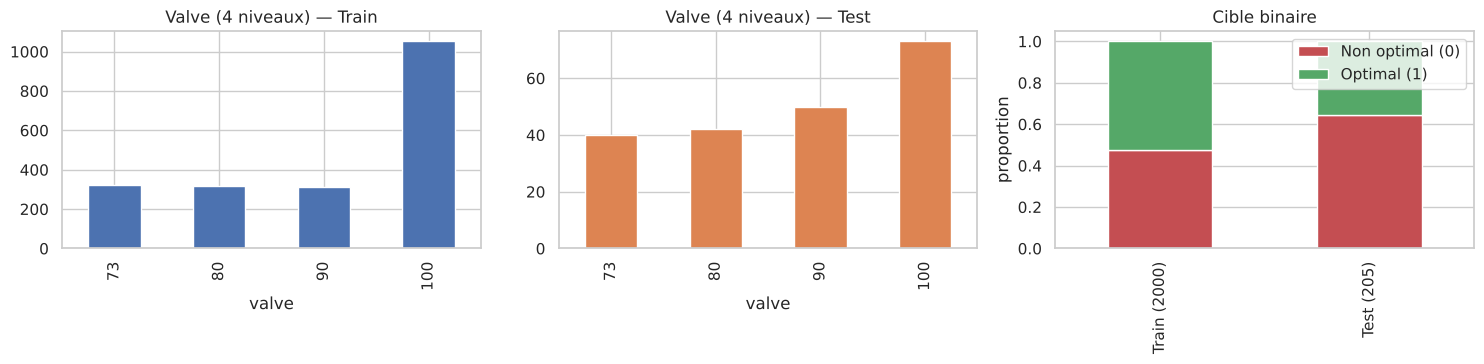

                 Train (2000)  Test (205)
Non optimal (0)         0.474       0.644
Optimal (1)             0.526       0.356


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
profile.valve.iloc[:N_TRAIN].value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Valve (4 niveaux) — Train")
profile.valve.iloc[N_TRAIN:].value_counts().sort_index().plot.bar(ax=ax[1], color="#DD8452"); ax[1].set_title("Valve (4 niveaux) — Test")
dist = pd.DataFrame({"Train (2000)": [np.mean(y_train == 0), np.mean(y_train == 1)],
                     "Test (205)": [np.mean(y_test == 0), np.mean(y_test == 1)]}, index=["Non optimal (0)", "Optimal (1)"])
dist.T.plot.bar(stacked=True, ax=ax[2], color=["#C44E52", "#55A868"]); ax[2].set_title("Cible binaire"); ax[2].set_ylabel("proportion")
plt.tight_layout(); plt.show()
print(dist.round(3))

**Points d'attention** : (i) en apprentissage les classes sont à peu près équilibrées (~53 % / 47 %), on n'a donc pas besoin de rééchantillonnage, mais on suivra **F1 et AUC** en plus de l'accuracy ; (ii) la proportion de valves optimales **diffère entre train et test** (le test est plus riche en cycles non optimaux) : c'est un *décalage de prior* à garder en tête lors de l'interprétation du test final.

### 1.5 Extraction de variables (feature engineering)
Chaque cycle est une série temporelle (6000 ou 600 points) : on la résume par des statistiques globales (tendance centrale, dispersion, forme, quantiles, pente, énergie, dynamique), et par la moyenne/écart-type sur 10 segments temporels consécutifs afin de conserver l'information sur *quand* les événements se produisent dans le cycle (phases de commutation de la valve).

In [7]:
def extract_features(X, name, n_seg=10):
    q = np.percentile(X, [5, 25, 50, 75, 95], axis=1)
    t = np.arange(X.shape[1]) - (X.shape[1] - 1) / 2
    d = np.diff(X, axis=1)
    f = {
        "mean": X.mean(1), "std": X.std(1), "min": X.min(1), "max": X.max(1), "ptp": np.ptp(X, axis=1),
        "median": q[2], "p05": q[0], "p25": q[1], "p75": q[3], "p95": q[4], "iqr": q[3] - q[1],
        "skew": stats.skew(X, axis=1), "kurt": stats.kurtosis(X, axis=1),
        "energy": (X ** 2).mean(1),
        "slope": ((t * (X - X.mean(1, keepdims=True))).sum(1)) / (t ** 2).sum(),
        "argmax": X.argmax(1) / X.shape[1], "argmin": X.argmin(1) / X.shape[1],
        "diff_mean_abs": np.abs(d).mean(1), "diff_max": d.max(1), "diff_min": d.min(1),
    }
    for i, seg in enumerate(np.array_split(X, n_seg, axis=1)):
        f[f"seg{i}_mean"] = seg.mean(1); f[f"seg{i}_std"] = seg.std(1)
    return pd.DataFrame({f"{name}_{k}": v for k, v in f.items()})

features = pd.concat([extract_features(ps2, "PS2"), extract_features(fs1, "FS1")], axis=1)
print("Nombre de variables :", features.shape[1], "| NaN :", int(features.isna().sum().sum()))
features = features.fillna(0.0)    # NaN éventuels = skew/kurt d'un signal constant
X_train, X_test = features.iloc[:N_TRAIN].reset_index(drop=True), features.iloc[N_TRAIN:].reset_index(drop=True)
feature_names = list(features.columns)
X_train.describe().T.head(12).round(3)

Nombre de variables : 80 | NaN : 0


,count,mean,std,min,25%,50%,75%,max
PS2_mean,2000.0,109.393,5.235,104.406,106.835,107.558,109.380,131.589
PS2_std,2000.0,47.775,3.432,45.203,46.153,46.639,47.158,59.548
PS2_min,2000.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
PS2_max,2000.0,166.450,0.998,155.040,166.100,166.570,167.020,167.740
PS2_ptp,2000.0,166.450,0.998,155.040,166.100,166.570,167.020,167.740
PS2_median,2000.0,128.554,3.619,124.445,127.025,127.810,129.875,165.400
PS2_p05,2000.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
PS2_p25,2000.0,117.997,1.715,112.840,116.480,117.930,120.060,120.690
PS2_p75,2000.0,132.728,12.020,125.040,127.645,128.300,130.470,165.560
PS2_p95,2000.0,141.474,8.938,134.690,137.480,138.350,140.280,165.850


### 1.6 Visualisations : signaux, histogrammes, boxplots

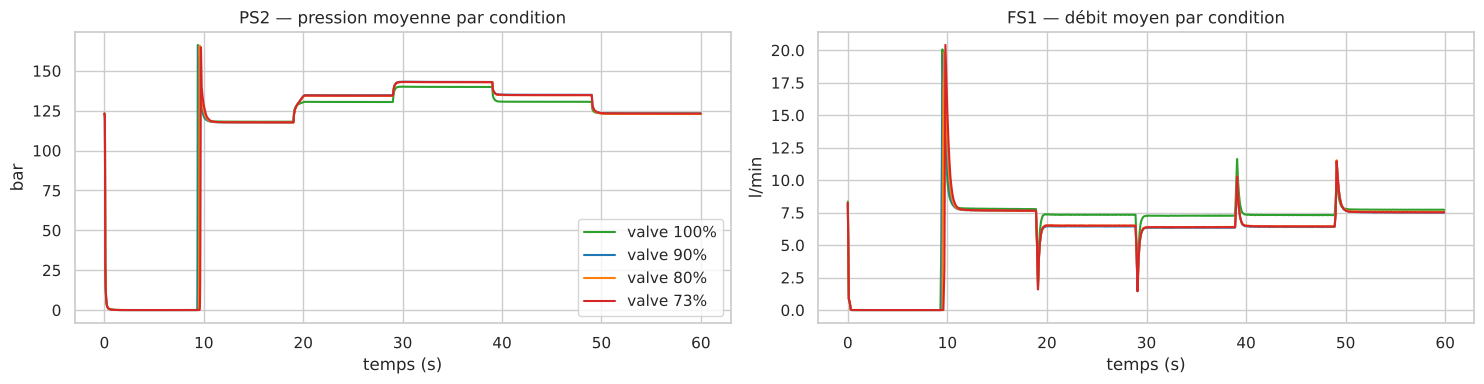

In [8]:
# Signaux moyens par niveau de condition de la valve
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for v, c in zip([100, 90, 80, 73], ["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728"]):
    m = (profile.valve.values[:N_TRAIN] == v)
    ax[0].plot(np.arange(6000) / 100, ps2[:N_TRAIN][m].mean(0), c=c, label=f"valve {v}%")
    ax[1].plot(np.arange(600) / 10, fs1[:N_TRAIN][m].mean(0), c=c, label=f"valve {v}%")
ax[0].set(title="PS2 — pression moyenne par condition", xlabel="temps (s)", ylabel="bar"); ax[1].set(title="FS1 — débit moyen par condition", xlabel="temps (s)", ylabel="l/min")
ax[0].legend(); plt.tight_layout(); plt.show()

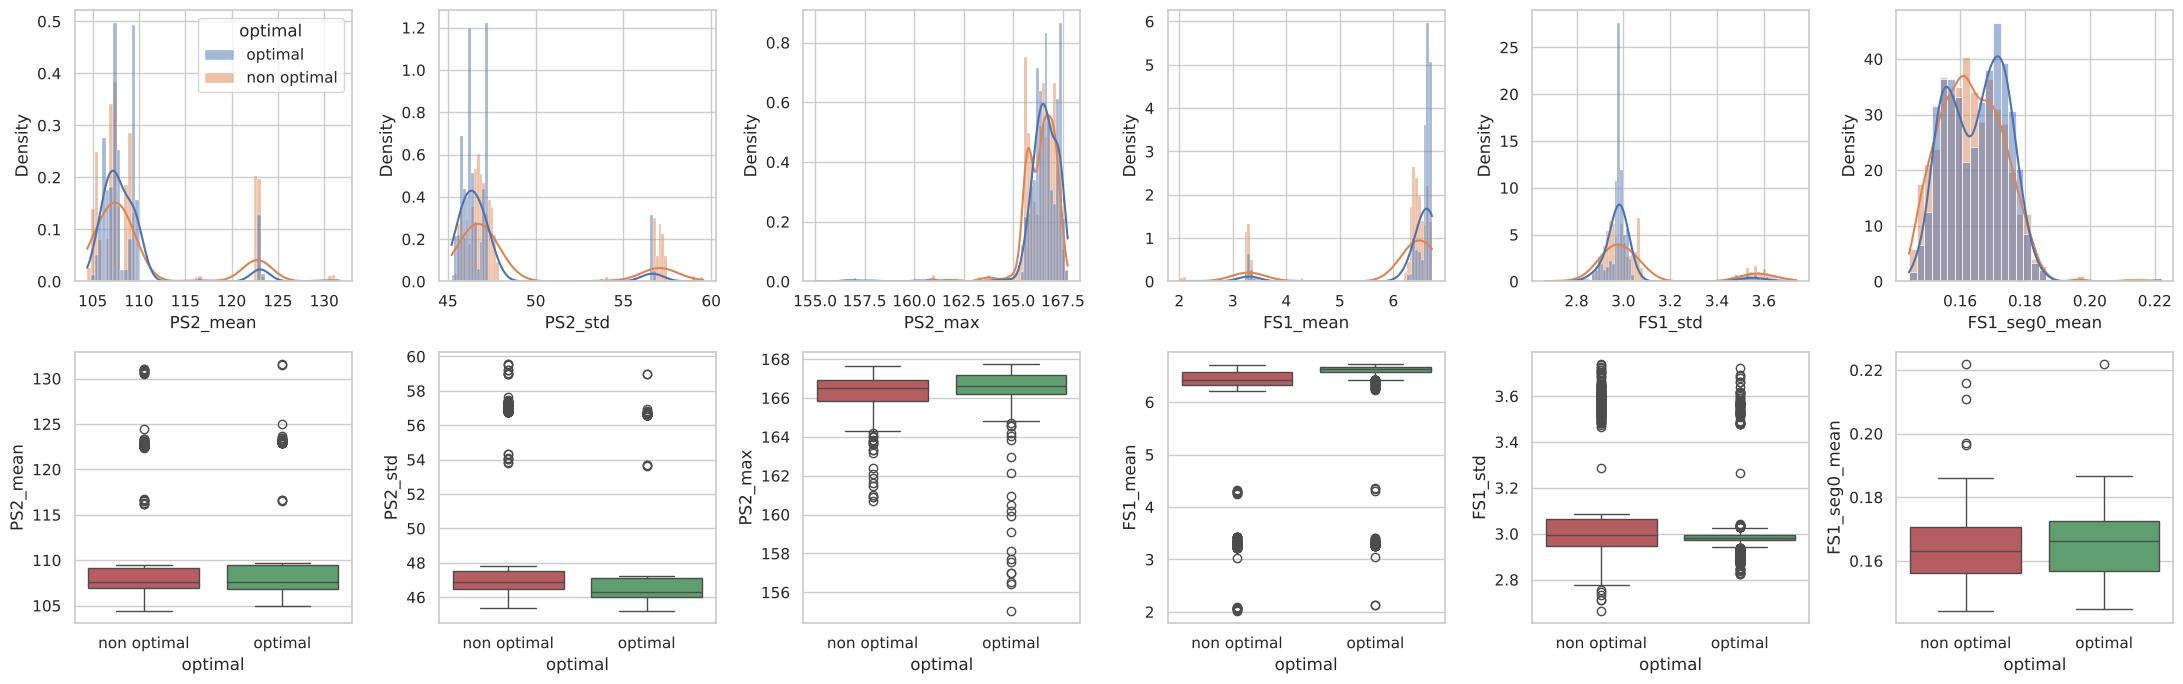

In [9]:
# Histogrammes et boxplots de quelques variables clés (par classe binaire)
show = ["PS2_mean", "PS2_std", "PS2_max", "FS1_mean", "FS1_std", "FS1_seg0_mean"]
df_vis = X_train.assign(optimal=np.where(y_train == 1, "optimal", "non optimal"))
fig, ax = plt.subplots(2, 6, figsize=(22, 7))
for i, c in enumerate(show):
    sns.histplot(data=df_vis, x=c, hue="optimal", kde=True, ax=ax[0, i], stat="density", common_norm=False, legend=(i == 0))
    sns.boxplot(data=df_vis, x="optimal", y=c, ax=ax[1, i], palette=["#C44E52", "#55A868"], order=["non optimal", "optimal"])
plt.tight_layout(); plt.show()

### 1.7 Analyse des corrélations

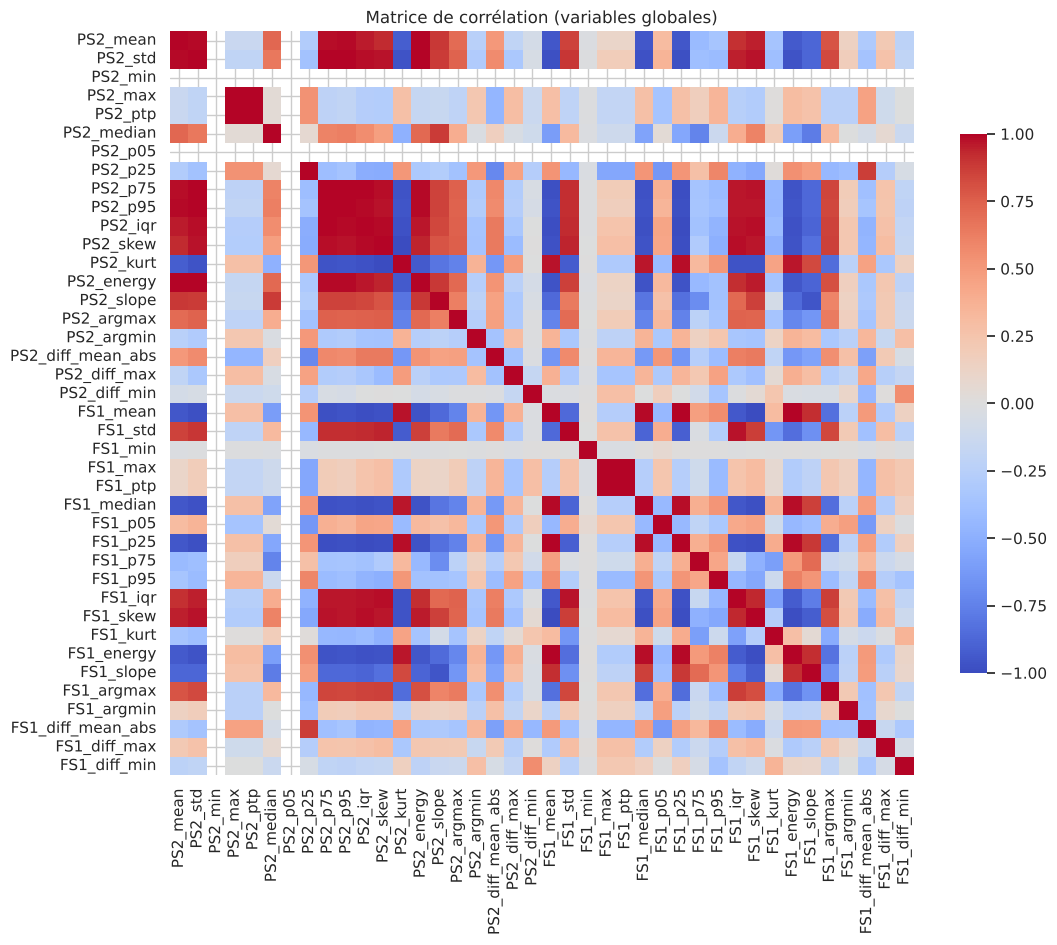

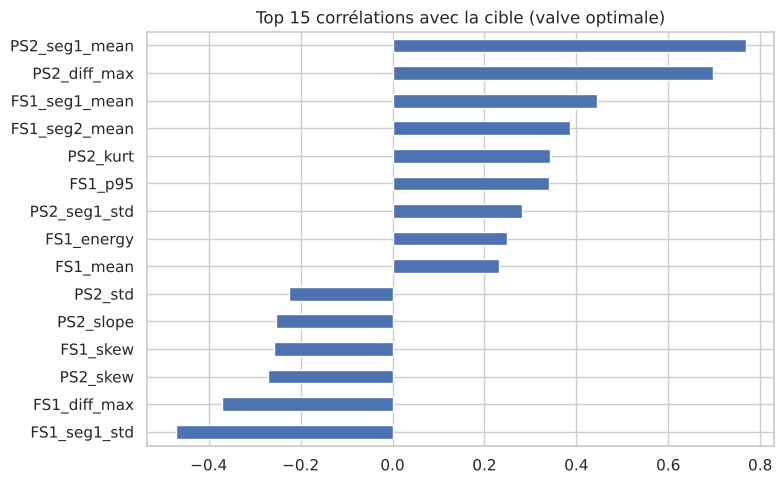

Paires de variables avec |corr| > 0.95 : 357  → forte redondance (filtre de corrélation dans le pipeline)


In [10]:
corr = X_train.corr()
# Matrice de corrélation (variables globales, hors segments, pour la lisibilité)
glob_cols = [c for c in feature_names if "seg" not in c]
plt.figure(figsize=(12, 10))
sns.heatmap(X_train[glob_cols].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=False, square=True, cbar_kws={"shrink": .7})
plt.title("Matrice de corrélation (variables globales)"); plt.show()

corr_target = X_train.apply(lambda s: np.corrcoef(s, y_train)[0, 1]).dropna()
top = corr_target.abs().sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5)); corr_target[top.index].sort_values().plot.barh(color="#4C72B0")
plt.title("Top 15 corrélations avec la cible (valve optimale)"); plt.tight_layout(); plt.show()

hi = (corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)) > 0.95).sum().sum()
print(f"Paires de variables avec |corr| > 0.95 : {hi}  → forte redondance (filtre de corrélation dans le pipeline)")

## 2. Sélection de variables (feature selection)
Quatre approches complémentaires, **calculées sur le train uniquement** : filtre de variance, filtre de redondance (|corr| > 0.95), méthodes univariées (ANOVA F, information mutuelle) et méthodes basées sur un modèle (importance Random Forest, régularisation L1).
Dans la modélisation, ces étapes sont **placées à l'intérieur du pipeline** : elles sont ainsi réajustées dans chaque pli de validation croisée, ce qui évite toute fuite d'information (*data leakage*).

In [11]:
class CorrFilter(BaseEstimator, TransformerMixin):
    """Supprime l'une des deux variables de chaque paire dont |corr| > threshold."""
    def __init__(self, threshold=0.95): self.threshold = threshold
    def fit(self, X, y=None):
        c = np.abs(np.corrcoef(np.asarray(X), rowvar=False)); c = np.nan_to_num(c)
        up = np.triu(c, k=1)
        self.keep_ = np.array([j for j in range(c.shape[0]) if not (up[:, j] > self.threshold).any()])
        return self
    def transform(self, X): return np.asarray(X)[:, self.keep_]

vt = VarianceThreshold(1e-10).fit(X_train); names_v = np.array(feature_names)[vt.get_support()]
cf = CorrFilter(0.95).fit(X_train[names_v]); names_c = names_v[cf.keep_]
print(f"{len(feature_names)} variables → {len(names_v)} après filtre de variance → {len(names_c)} après filtre de corrélation")

Xs = RobustScaler().fit_transform(X_train[names_c])
f_scores, _ = f_classif(Xs, y_train)
mi = mutual_info_classif(Xs, y_train, random_state=RANDOM_STATE)
rf_imp = RandomForestClassifier(300, random_state=RANDOM_STATE, n_jobs=-1).fit(Xs, y_train).feature_importances_
l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.1).fit(Xs, y_train); l1_coef = np.abs(l1.coef_[0])

sel_table = pd.DataFrame({"ANOVA_F": f_scores, "MutualInfo": mi, "RF_importance": rf_imp, "L1_|coef|": l1_coef}, index=names_c)
rank = sel_table.rank(ascending=False)
sel_table["rang_moyen"] = rank.mean(1)
display(sel_table.sort_values("rang_moyen").head(15).round(3))

top10 = {m: set(sel_table[m].sort_values(ascending=False).head(10).index) for m in ["ANOVA_F", "MutualInfo", "RF_importance", "L1_|coef|"]}
consensus = set.intersection(*top10.values())
print("Variables dans le top 10 des 4 méthodes :", sorted(consensus) if consensus else "aucune (consensus partiel ci-dessus)")

80 variables → 78 après filtre de variance → 40 après filtre de corrélation


,ANOVA_F,MutualInfo,RF_importance,L1_|coef|,rang_moyen
PS2_seg1_mean,2874.071,0.522,0.186,9.686,1.500
FS1_seg1_std,571.892,0.150,0.053,1.826,6.000
PS2_argmax,85.058,0.645,0.259,0.002,7.500
PS2_slope,137.258,0.317,0.045,0.116,8.000
FS1_argmax,62.364,0.436,0.168,0.006,9.000
FS1_seg1_mean,492.384,0.181,0.040,0.088,9.500
PS2_diff_max,1885.723,0.379,0.065,0.000,9.875
FS1_p95,262.322,0.107,0.006,0.094,13.500
PS2_diff_mean_abs,15.949,0.194,0.007,0.649,14.000
FS1_p75,71.311,0.226,0.036,0.000,14.125


Variables dans le top 10 des 4 méthodes : ['PS2_seg1_mean']


## 3. Modélisation
### 3.1 Choix des modèles (justification)
| Modèle | Nature | Pourquoi pour ces données |
|---|---|---|
| Régression logistique | linéaire | Baseline interprétable ; teste si la frontière est linéaire. Variables mises à l'échelle (RobustScaler) et décorrélées. |
| k-NN | non linéaire, local | Sans hypothèse de distribution ; sensible au bruit et à l'échelle → scaling + sélection de variables. |
| Arbre de décision | non linéaire | Interprétable, robuste aux valeurs extrêmes, gère des seuils physiques (ex. pression max). Variance élevée. |
| Naive Bayes gaussien | linéaire/quadratique, probabiliste | Rapide ; suppose l'indépendance conditionnelle et des lois gaussiennes — hypothèse **violée** ici (variables très corrélées), il sert de référence. |
| SVM (RBF) | non linéaire à noyau | Adapté aux variables continues et au bruit modéré ; bon en petite/moyenne dimension. |
| Random Forest / Extra Trees / HistGradientBoosting | ensembles non linéaires | Réduisent la variance (bagging) ou le biais (boosting) ; robustes au bruit et aux outliers ; capturent les interactions entre signaux. |

In [12]:
def make_pipe(clf, scale=True, k=20):
    return Pipeline([("var", VarianceThreshold(1e-10)),
                     ("corr", CorrFilter(0.95)),
                     ("scale", RobustScaler() if scale else "passthrough"),
                     ("sel", SelectKBest(f_classif, k=k)),
                     ("clf", clf)])

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "k-NN":                make_pipe(KNeighborsClassifier()),
    "Decision Tree":       make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False),
    "Naive Bayes":         make_pipe(GaussianNB()),
    "SVM (RBF)":           make_pipe(SVC(random_state=RANDOM_STATE)),
    "Random Forest":       make_pipe(RandomForestClassifier(300, random_state=RANDOM_STATE, n_jobs=-1), scale=False),
    "Extra Trees":         make_pipe(ExtraTreesClassifier(300, random_state=RANDOM_STATE, n_jobs=-1), scale=False),
    "HistGradBoosting":    make_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

## 4. Évaluation des modèles (baseline, hyperparamètres par défaut, validation croisée 5-fold stratifiée sur les 2000 cycles)

In [13]:
rows = []
for name, pipe in models.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=1)
    rows.append({"Modèle": name,
                 **{m.capitalize(): r[f"test_{m}"].mean() for m in scoring},
                 "F1 std": r["test_f1"].std(), "F1 train": r["train_f1"].mean(),
                 "Écart train-val (F1)": r["train_f1"].mean() - r["test_f1"].mean()})
baseline = pd.DataFrame(rows).set_index("Modèle").sort_values("F1", ascending=False)
display(baseline.round(4))

,Accuracy,Precision,Recall,F1,Roc_auc,F1 std,F1 train,Écart train-val (F1)
Modèle,,,,,,,,
Extra Trees,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000
Random Forest,0.9995,1.0000,0.9990,0.9995,1.0000,0.0010,1.0000,0.0005
HistGradBoosting,0.9985,0.9991,0.9981,0.9986,0.9992,0.0012,1.0000,0.0014
Decision Tree,0.9970,0.9981,0.9962,0.9971,0.9970,0.0018,1.0000,0.0029
Logistic Regression,0.9965,0.9953,0.9981,0.9967,0.9996,0.0024,0.9986,0.0019
k-NN,0.9660,0.9687,0.9667,0.9676,0.9914,0.0070,0.9805,0.0129
SVM (RBF),0.8345,0.7893,0.9363,0.8562,0.9479,0.0123,0.8559,-0.0003
Naive Bayes,0.8250,0.7819,0.9278,0.8481,0.9224,0.0171,0.8475,-0.0006


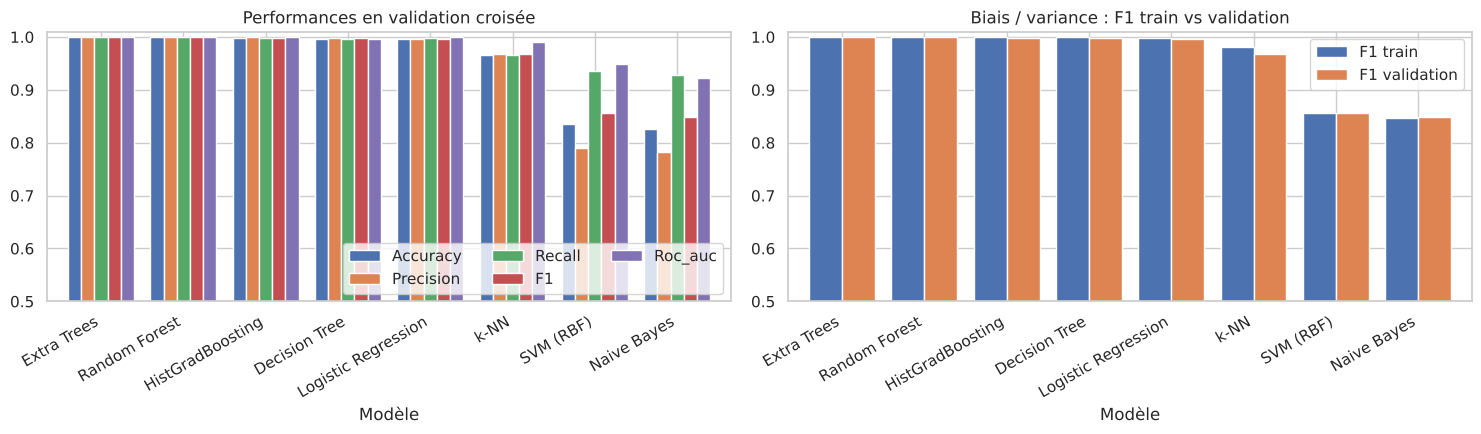

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
baseline[["Accuracy", "Precision", "Recall", "F1", "Roc_auc"]].plot.bar(ax=ax[0], width=.8); ax[0].set_ylim(.5, 1.01); ax[0].set_title("Performances en validation croisée"); ax[0].legend(loc="lower right", ncol=3)
bv = baseline[["F1 train", "F1"]].rename(columns={"F1": "F1 validation"}); bv.plot.bar(ax=ax[1], width=.8); ax[1].set_ylim(.5, 1.01); ax[1].set_title("Biais / variance : F1 train vs validation")
plt.setp(ax[0].get_xticklabels(), rotation=30, ha="right"); plt.setp(ax[1].get_xticklabels(), rotation=30, ha="right"); plt.tight_layout(); plt.show()

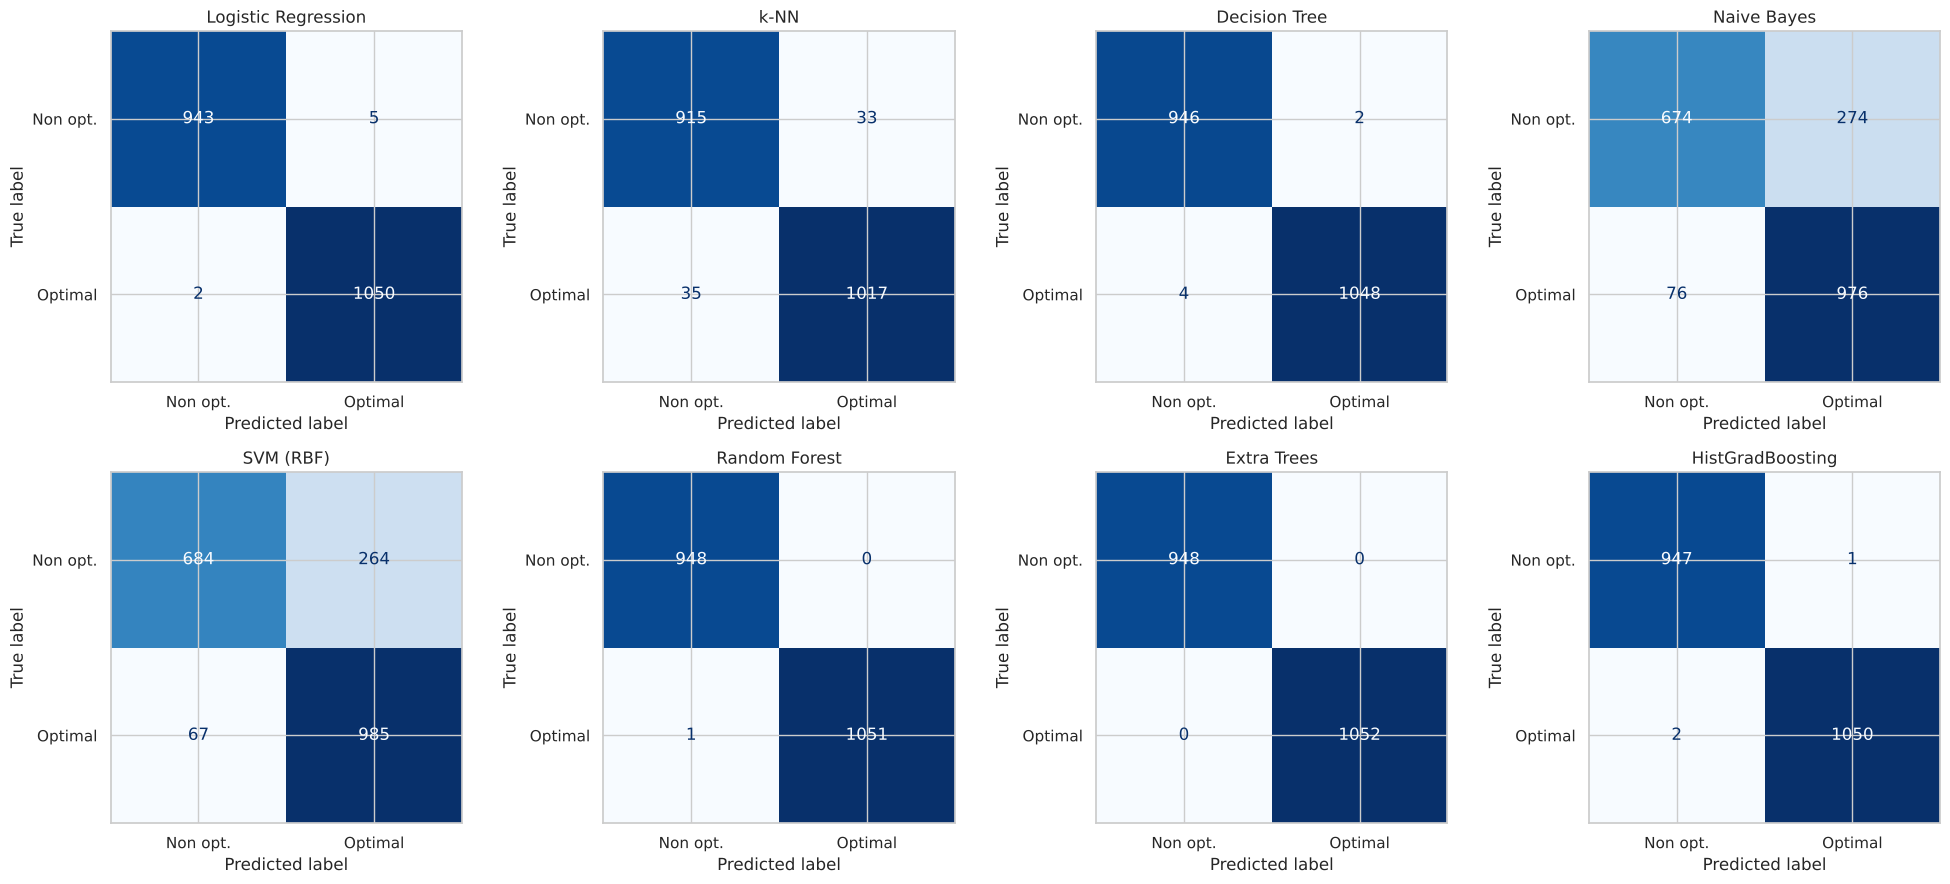

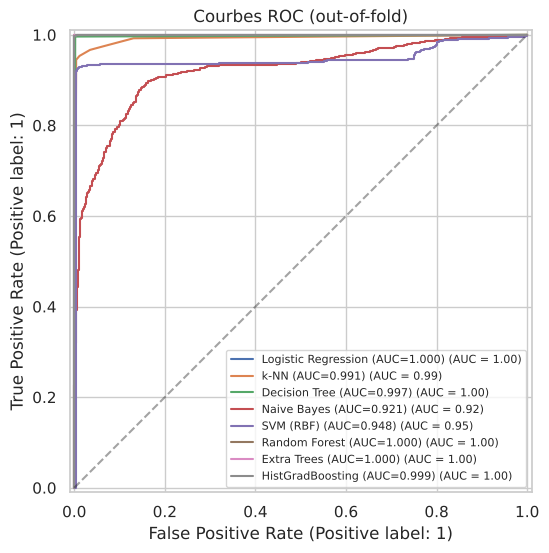

In [15]:
# Matrices de confusion et courbes ROC (prédictions out-of-fold sur le train)
def oof_scores(pipe):
    m = "predict_proba" if hasattr(pipe, "predict_proba") else "decision_function"
    s = cross_val_predict(pipe, X_train, y_train, cv=cv, method=m)
    return s[:, 1] if s.ndim == 2 else s

fig, ax = plt.subplots(2, 4, figsize=(20, 9)); ax = ax.ravel()
fig_roc, ax_roc = plt.subplots(figsize=(7, 6))
for i, (name, pipe) in enumerate(models.items()):
    pred = cross_val_predict(pipe, X_train, y_train, cv=cv)
    ConfusionMatrixDisplay.from_predictions(y_train, pred, display_labels=["Non opt.", "Optimal"], ax=ax[i], colorbar=False, cmap="Blues")
    ax[i].set_title(name)
    RocCurveDisplay.from_predictions(y_train, oof_scores(pipe), name=f"{name} (AUC={roc_auc_score(y_train, oof_scores(pipe)):.3f})", ax=ax_roc)
ax_roc.plot([0, 1], [0, 1], "k--", alpha=.4); ax_roc.set_title("Courbes ROC (out-of-fold)"); ax_roc.legend(loc="lower right", fontsize=8)
fig.tight_layout(); plt.show()

**Lecture** : sans réglage, les ensembles d'arbres (Extra Trees, Random Forest, HistGradientBoosting), l'arbre seul et même la régression logistique dépassent 99,6 % de F1 avec un écart train/validation quasi nul (ou de l'ordre de 0,3 %) : très peu de variance, très peu de biais. Le k-NN est un cran en dessous (F1 ≈ 0,97, écart train/val ≈ 1,3 %, signe d'un peu de variance : il souffre des variables bruitées et de la dimension). SVM-RBF et Naive Bayes plafonnent vers 0,85 : le SVM avec gamma par défaut est mal réglé (sous-apprentissage, biais élevé, corrigé par la recherche d'hyperparamètres), et Naive Bayes est pénalisé par l'hypothèse d'indépendance, violée ici (plus de 350 paires de variables corrélées à plus de 0,95).

## 5. Optimisation des hyperparamètres
**Grid Search** (recherche exhaustive) pour les modèles à peu d'hyperparamètres (LR, k-NN, SVM, Naive Bayes) et **Random Search** (tirage aléatoire) pour les modèles à grand espace (arbre, forêts, boosting). Le nombre de variables conservées (`sel__k`) fait partie de la recherche. Score optimisé : **F1**, évalué en validation croisée 5-fold stratifiée (la sélection ne voit jamais le test final).

In [16]:
K = [10, 20, 30]
searches = {
 "Logistic Regression": GridSearchCV(models["Logistic Regression"], {"sel__k": K, "clf__C": [0.01, 0.1, 1, 10, 100]}, cv=cv, scoring="f1", n_jobs=-1),
 "k-NN": GridSearchCV(models["k-NN"], {"sel__k": K, "clf__n_neighbors": [3, 5, 7, 11, 15, 21], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}, cv=cv, scoring="f1", n_jobs=-1),
 "Naive Bayes": GridSearchCV(models["Naive Bayes"], {"sel__k": K, "clf__var_smoothing": np.logspace(-11, -1, 6)}, cv=cv, scoring="f1", n_jobs=-1),
 "SVM (RBF)": GridSearchCV(models["SVM (RBF)"], {"sel__k": K, "clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.1, 0.01, 0.001]}, cv=cv, scoring="f1", n_jobs=-1),
 "Decision Tree": RandomizedSearchCV(models["Decision Tree"], {"sel__k": K, "clf__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "clf__min_samples_leaf": randint(1, 30), "clf__criterion": ["gini", "entropy"]}, n_iter=40, cv=cv, scoring="f1", n_jobs=-1, random_state=RANDOM_STATE),
 "Random Forest": RandomizedSearchCV(models["Random Forest"], {"sel__k": K, "clf__n_estimators": randint(100, 500), "clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": randint(1, 10), "clf__max_features": ["sqrt", "log2", 0.5]}, n_iter=20, cv=cv, scoring="f1", n_jobs=1, random_state=RANDOM_STATE),
 "Extra Trees": RandomizedSearchCV(models["Extra Trees"], {"sel__k": K, "clf__n_estimators": randint(100, 500), "clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": randint(1, 10), "clf__max_features": ["sqrt", "log2", 0.5]}, n_iter=20, cv=cv, scoring="f1", n_jobs=1, random_state=RANDOM_STATE),
 "HistGradBoosting": RandomizedSearchCV(models["HistGradBoosting"], {"sel__k": K, "clf__learning_rate": loguniform(0.01, 0.3), "clf__max_depth": [2, 3, 4, 6, None], "clf__max_iter": randint(100, 400), "clf__l2_regularization": loguniform(1e-3, 10), "clf__min_samples_leaf": randint(10, 60)}, n_iter=20, cv=cv, scoring="f1", n_jobs=1, random_state=RANDOM_STATE),
}
tuned = {}
for name, s in searches.items():
    s.fit(X_train, y_train); tuned[name] = s
    print(f"{name:20s} F1 CV = {s.best_score_:.4f}  | {s.best_params_}")

Logistic Regression  F1 CV = 1.0000  | {'clf__C': 10, 'sel__k': 10}


k-NN                 F1 CV = 0.9861  | {'clf__n_neighbors': 15, 'clf__p': 1, 'clf__weights': 'distance', 'sel__k': 10}


Naive Bayes          F1 CV = 0.8791  | {'clf__var_smoothing': np.float64(1e-11), 'sel__k': 10}


SVM (RBF)            F1 CV = 0.9914  | {'clf__C': 100, 'clf__gamma': 0.01, 'sel__k': 10}


Decision Tree        F1 CV = 0.9981  | {'clf__criterion': 'entropy', 'clf__max_depth': 6, 'clf__min_samples_leaf': 2, 'sel__k': 20}


Random Forest        F1 CV = 0.9995  | {'clf__max_depth': 12, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3, 'clf__n_estimators': 406, 'sel__k': 30}


Extra Trees          F1 CV = 1.0000  | {'clf__max_depth': 6, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 7, 'clf__n_estimators': 430, 'sel__k': 30}


HistGradBoosting     F1 CV = 0.9995  | {'clf__l2_regularization': np.float64(0.027155819552829405), 'clf__learning_rate': np.float64(0.014830392684568025), 'clf__max_depth': 2, 'clf__max_iter': 367, 'clf__min_samples_leaf': 43, 'sel__k': 10}


In [17]:
# Modèles optimisés : performances complètes en validation croisée (réévaluation avec les meilleurs hyperparamètres)
rows = []
for name, s in tuned.items():
    r = cross_validate(s.best_estimator_, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    rows.append({"Modèle": name, **{m.capitalize(): r[f"test_{m}"].mean() for m in scoring},
                 "F1 std": r["test_f1"].std(), "Écart train-val (F1)": r["train_f1"].mean() - r["test_f1"].mean(),
                 "F1 baseline": baseline.loc[name, "F1"]})
tuned_cv = pd.DataFrame(rows).set_index("Modèle").sort_values("F1", ascending=False)
tuned_cv["Gain F1"] = tuned_cv["F1"] - tuned_cv["F1 baseline"]
display(tuned_cv.round(4))
best_name = tuned_cv.index[0]; best_model = tuned[best_name].best_estimator_
print("Meilleur modèle (CV, F1) :", best_name)
ties = tuned_cv.index[tuned_cv["F1"] >= tuned_cv["F1"].max() - 1e-9].tolist()
print("Modèles à égalité parfaite en CV :", ties, "→ à égalité on retient le plus simple (parcimonie).")

,Accuracy,Precision,Recall,F1,Roc_auc,F1 std,Écart train-val (F1),F1 baseline,Gain F1
Modèle,,,,,,,,,
Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.9967,0.0033
Extra Trees,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000
Random Forest,0.9995,1.0000,0.9990,0.9995,1.0000,0.0010,0.0005,0.9995,0.0000
HistGradBoosting,0.9995,1.0000,0.9990,0.9995,1.0000,0.0010,0.0005,0.9986,0.0010
Decision Tree,0.9980,0.9991,0.9971,0.9981,0.9980,0.0010,0.0013,0.9971,0.0009
SVM (RBF),0.9910,0.9943,0.9886,0.9914,0.9985,0.0047,0.0086,0.8562,0.1352
k-NN,0.9855,0.9934,0.9791,0.9861,0.9985,0.0033,0.0139,0.9676,0.0185
Naive Bayes,0.8665,0.8410,0.9220,0.8791,0.9475,0.0175,0.0002,0.8481,0.0310


Meilleur modèle (CV, F1) : Logistic Regression
Modèles à égalité parfaite en CV : ['Logistic Regression', 'Extra Trees'] → à égalité on retient le plus simple (parcimonie).


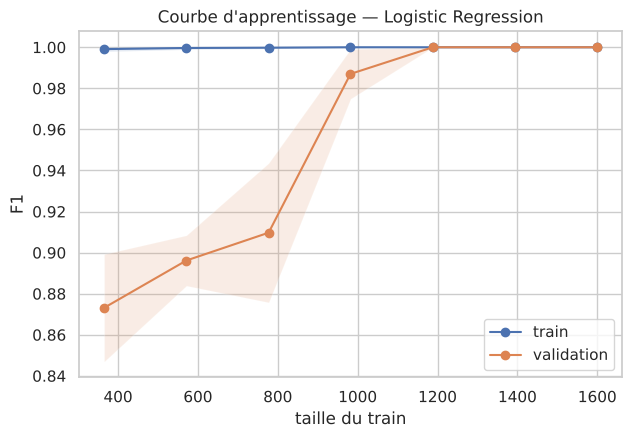

In [18]:
# Courbe d'apprentissage du meilleur modèle : diagnostic biais / variance
sizes, tr, va = learning_curve(best_model, X_train, y_train, cv=cv, scoring="f1", train_sizes=np.linspace(.1, 1, 8), n_jobs=-1)
plt.figure(figsize=(7, 4.5))
plt.plot(sizes, tr.mean(1), "o-", label="train"); plt.fill_between(sizes, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), alpha=.15)
plt.plot(sizes, va.mean(1), "o-", label="validation"); plt.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.15)
plt.xlabel("taille du train"); plt.ylabel("F1"); plt.title(f"Courbe d'apprentissage — {best_name}"); plt.legend(); plt.show()

## 6. Évaluation finale sur l'échantillon de test (205 derniers cycles)
Le test n'a servi à **aucun** choix (features, sélection, hyperparamètres, modèle). On l'utilise une seule fois pour estimer la performance de généralisation. Tous les modèles optimisés sont reportés pour information, mais **le modèle retenu est celui choisi en validation croisée**.

In [19]:
def test_metrics(est):
    p = est.predict(X_test)
    s = est.predict_proba(X_test)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    return {"Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p),
            "F1": f1_score(y_test, p), "ROC AUC": roc_auc_score(y_test, s), "Spécificité (non opt. détectés)": tn / (tn + fp)}
final = pd.DataFrame({n: test_metrics(s.best_estimator_) for n, s in tuned.items()}).T.sort_values("F1", ascending=False)
display(final.round(4)); print("Modèle retenu (choisi en CV) :", best_name)

,Accuracy,Precision,Recall,F1,ROC AUC,Spécificité (non opt. détectés)
Logistic Regression,1.0000,1.0000,1.0,1.0000,1.0000,1.0000
SVM (RBF),1.0000,1.0000,1.0,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0,1.0000,1.0000,1.0000
Decision Tree,1.0000,1.0000,1.0,1.0000,1.0000,1.0000
Extra Trees,1.0000,1.0000,1.0,1.0000,1.0000,1.0000
HistGradBoosting,1.0000,1.0000,1.0,1.0000,1.0000,1.0000
k-NN,0.8732,0.7374,1.0,0.8488,0.9659,0.8030
Naive Bayes,0.6293,0.4899,1.0,0.6577,0.9060,0.4242


Modèle retenu (choisi en CV) : Logistic Regression


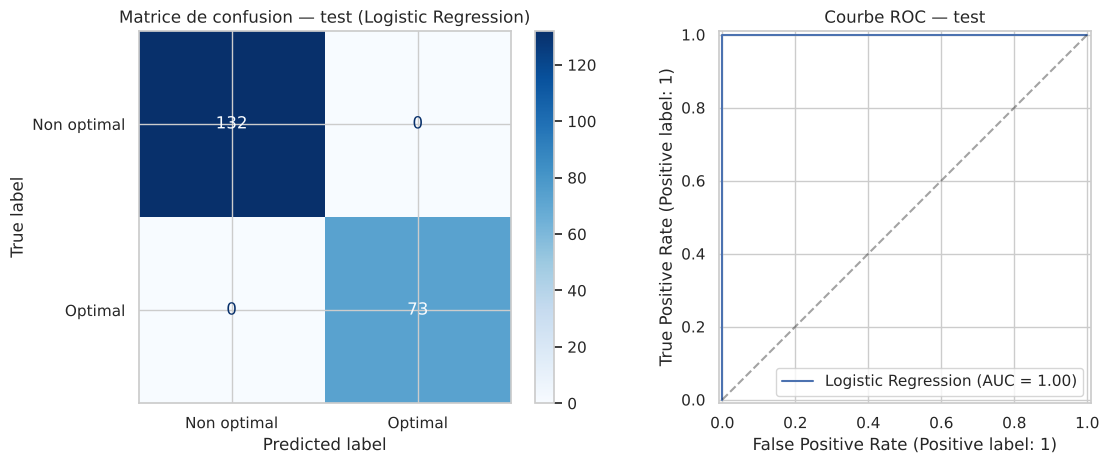

,taux d'erreur,erreurs,cycles
valve,,,
73,0.0,0,40
80,0.0,0,42
90,0.0,0,50
100,0.0,0,73


CV (F1) = 1.0000  vs  test (F1) = 1.0000


In [20]:
pred = best_model.predict(X_test)
score = best_model.predict_proba(X_test)[:, 1] if hasattr(best_model, "predict_proba") else best_model.decision_function(X_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Non optimal", "Optimal"], ax=ax[0], cmap="Blues"); ax[0].set_title(f"Matrice de confusion — test ({best_name})")
RocCurveDisplay.from_predictions(y_test, score, name=best_name, ax=ax[1]); ax[1].plot([0, 1], [0, 1], "k--", alpha=.4); ax[1].set_title("Courbe ROC — test")
plt.tight_layout(); plt.show()

# Erreurs par niveau de condition (où le modèle se trompe-t-il ?)
err = pd.DataFrame({"valve": profile.valve.values[N_TRAIN:], "erreur": pred != y_test})
display(err.groupby("valve").erreur.agg(["mean", "sum", "count"]).rename(columns={"mean": "taux d'erreur", "sum": "erreurs", "count": "cycles"}).round(3))
print(f"CV (F1) = {tuned_cv.loc[best_name, 'F1']:.4f}  vs  test (F1) = {f1_score(y_test, pred):.4f}")

## 7. Interprétation : quelles variables expliquent une valve non optimale ?

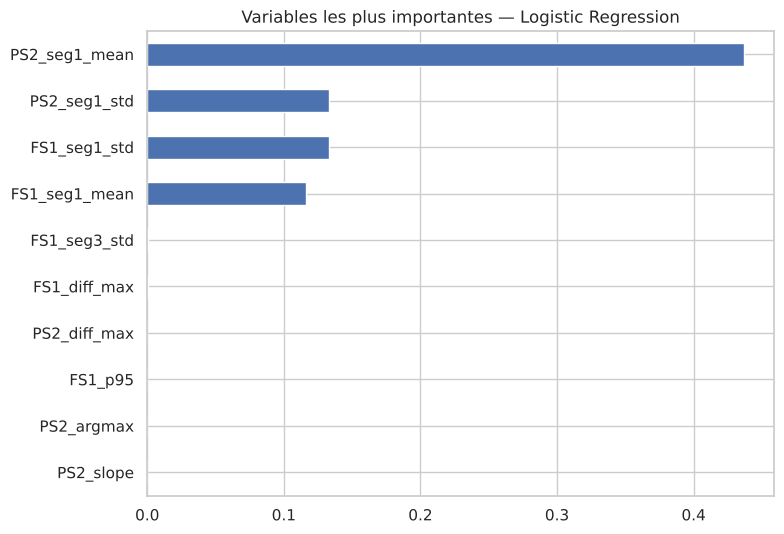

Part de l'importance portée par PS2 : 0.695 | FS1 : 0.305


In [21]:
sel_names = np.array(feature_names)
sel_names = sel_names[best_model.named_steps["var"].get_support()][best_model.named_steps["corr"].keep_][best_model.named_steps["sel"].get_support()]
clf = best_model.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=sel_names)
else:
    from sklearn.inspection import permutation_importance
    Xt = best_model[:-1].transform(X_train)
    imp = pd.Series(permutation_importance(clf, Xt, y_train, n_repeats=10, random_state=RANDOM_STATE, scoring="f1").importances_mean, index=sel_names)
imp.sort_values().tail(15).plot.barh(figsize=(8, 5.5), color="#4C72B0"); plt.title(f"Variables les plus importantes — {best_name}"); plt.tight_layout(); plt.show()
print("Part de l'importance portée par PS2 :", round(imp[imp.index.str.startswith('PS2')].sum() / imp.sum(), 3), "| FS1 :", round(imp[imp.index.str.startswith('FS1')].sum() / imp.sum(), 3))

## 8. Sauvegarde du modèle et prédiction pour un numéro de cycle (bonus)

In [22]:
joblib.dump({"model": best_model, "feature_names": feature_names}, "best_valve_model.joblib")
features.to_csv("features_all_cycles.csv", index=False)

def predict_cycle(n):
    """Prédiction pour le cycle n (1 = premier cycle)."""
    i = n - 1; x = features.iloc[[i]]
    p = int(best_model.predict(x)[0]); true = int(y_all[i])
    proba = best_model.predict_proba(x)[0, 1] if hasattr(best_model, "predict_proba") else float("nan")
    print(f"Cycle {n} : prédit = {'OPTIMAL' if p else 'NON OPTIMAL'} (P(optimal) = {proba:.2f}) | réel = {'optimal' if true else 'non optimal'} (valve {profile.valve[i]}%)")
for n in [1, 500, 2001, 2150]:
    predict_cycle(n)

Cycle 1 : prédit = OPTIMAL (P(optimal) = 1.00) | réel = optimal (valve 100%)
Cycle 500 : prédit = NON OPTIMAL (P(optimal) = 0.01) | réel = non optimal (valve 90%)
Cycle 2001 : prédit = NON OPTIMAL (P(optimal) = 0.00) | réel = non optimal (valve 80%)
Cycle 2150 : prédit = OPTIMAL (P(optimal) = 0.99) | réel = optimal (valve 100%)


## 9. Conclusion
- **Données** : 2205 cycles, aucune valeur manquante ; classes équilibrées en apprentissage (52,6 % optimal), mais le test est plus riche en cycles non optimaux (64 %) : le modèle y reste parfait, donc la détection ne dépend pas de la proportion de classes.
- **Variables** : 80 variables extraites des signaux, 40 après filtres de variance/corrélation ; la plus discriminante, de loin, est `PS2_seg1_mean` (pression moyenne sur le 2e des 10 segments du cycle, soit de 6 à 12 s, fenêtre qui contient la montée en pression d'environ 9,5 s). Les variables de pression portent environ 70 % de l'importance, le débit FS1 environ 30 %.
- **Modèles** : les modèles linéaires comme non linéaires atteignent F1 ≈ 1 après optimisation, ce qui montre que le problème est **quasi linéairement séparable** une fois les bonnes variables extraites. Naive Bayes est nettement derrière (hypothèse d'indépendance violée).
- **Choix final** : Logistic Regression, à égalité parfaite en CV avec Extra Trees ; à performance égale on retient le modèle le plus simple, le plus rapide et le plus interprétable (biais/variance : écart train/val nul). Résultat test : 205/205 cycles correctement classés.
- **Réserves** : un score de 100 % sur 205 cycles ne prouve pas l'infaillibilité (l'intervalle de confiance à 95 % de l'accuracy reste d'environ [98,2 % ; 100 %]) ; les cycles viennent d'une seule machine et d'une même campagne de mesure, la performance sur une autre installation n'est pas garantie. Les erreurs possibles en production sont à surveiller surtout côté « non optimal détecté comme optimal » (coût de maintenance).